# 04. 베이스라인 — TF-IDF + 로지스틱 회귀

**목표:** 속성 8개 × {0 미언급, 1 긍정, 2 보통, 3 부정}을 예측하는 **고전 ML 베이스라인**을 학습하고, 05의 제안 모델(KLUE-RoBERTa)과 비교할 기준점을 만든다.

| 항목 | 내용 |
|---|---|
| 입력 | 정제된 리뷰 텍스트(`src/preprocess.clean_text` 적용본) |
| 특징 | TF-IDF **글자 n-gram(2~4, 단어 경계 기준)** — 한국어는 조사·어미가 붙어 단어 단위가 잘게 깨지므로 형태소 분석기 없이도 강건한 글자 n-gram을 사용 |
| 분류기 | 속성별 **로지스틱 회귀 8개** (다중 클래스, `class_weight="balanced"`로 미언급 쏠림 완화) |
| 튜닝 | 속성마다 규제 강도 `C`를 **Validation Macro-F1** 기준으로 선택 |
| 학습 방식 | Scratch (사전학습 없음) |

**평가 지표** (`src/absa.py` — 05와 동일한 함수 사용)
- **주지표: 속성 평균 Macro-F1** — 속성별 4클래스 Macro-F1의 평균. 정답·예측 어디에도 없는 클래스는 평균에서 제외
- 보조: Accuracy, **언급 감지 F1**(미언급 vs 언급) — 사운드처럼 테스트 언급이 매우 적은 속성은 Macro-F1 변동이 커서 함께 보고

**종합 평가(overall):** 속성이 모두 미언급인 은유적·총평형 리뷰("소매치기만 하고 다니다 보니 현실에서도 하고 싶어요..")를 위해 **추천/비추천**을 따로 예측한다. 정답은 작성자가 누른 추천 버튼(`voted_up`)이라 추가 라벨링 없이 정제 데이터 전체(Test·Val 제외 10,677건)로 학습한다.

**산출물:** `models/baseline.joblib`, `results/baseline_metrics.json`, `results/baseline_test_pred.csv`, `figures/04_*.png`

In [1]:
# ── 환경 설정 ────────────────────────────────────────────
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")       # Drive 연결 위치(수정 X)

# ▶ 프로젝트 폴더 경로 (01 노트북과 동일하게)
def find_root():
    """프로젝트 폴더 자동 탐색. Drive의 한글 폴더명이 NFD(자모 분리)로 저장되면
    "ML 기말" 같은 문자열 경로가 일치하지 않으므로, MyDrive를 직접 훑어
    data/processed/reviews_clean.csv가 있는 폴더를 찾는다(검수 파일이 있는 쪽 우선)."""
    if os.environ.get("ML_ROOT"):
        return Path(os.environ["ML_ROOT"])
    base = Path("/content/drive/MyDrive")
    cands = [p for p in [base, *base.glob("*"), *base.glob("*/*")]
             if p.is_dir() and (p / "data" / "processed" / "reviews_clean.csv").exists()]
    if not cands:
        print("⚠ 프로젝트 폴더를 찾지 못해 기본 경로를 사용합니다.")
        return base / "ML 기말"
    cands.sort(key=lambda p: not (p / "data" / "labeling" / "test_verify.csv").exists())
    if len(cands) > 1:
        print("⚠ 프로젝트 폴더 후보가 여러 개입니다 → 첫 번째 사용:", *cands, sep="\n   ")
    return cands[0]

ROOT = find_root()
sys.path.append(str(ROOT / "src"))      # src/preprocess.py 등 공용 모듈
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT, "| exists:", ROOT.exists())

Mounted at /content/drive
ROOT: /content/drive/MyDrive/머신러닝 포트폴리오 | exists: True


In [2]:
import json, time
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score

from absa import (ASPECTS, ASPECTS_KO, LABELS, LABEL_NAMES, LABEL_NAMES_EN, OVERALL_NAMES,
                  load_splits, load_overall_splits, evaluate, summary, aspect_macro_f1, overall_metrics,
                  human_subset_report)
from preprocess import clean_text

SEED = 42
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)
RES_DIR = ROOT / "results"; RES_DIR.mkdir(exist_ok=True)

train, val, test, TEST_SOURCE = load_splits(ROOT)
Y_tr, Y_va, Y_te = (d[ASPECTS].values.astype(int) for d in (train, val, test))

Train 1500 / Val 200 / Test 300  (테스트 라벨: LLM — 사람 검수는 참고용으로만 비교)


## 1. 분할별 클래스 분포

Train에는 희소 속성 보강 풀(1,000건)이 포함되어 있고, Val·Test는 무작위 풀에서만 뽑아 **실제 분포**를 따른다.

In [3]:
def dist_table(Y, name):
    t = pd.DataFrame({ko: pd.Series(Y[:, j]).value_counts().reindex(LABELS, fill_value=0)
                      for j, ko in enumerate(ASPECTS_KO)}).T
    t.columns = [LABEL_NAMES[c] for c in LABELS]
    t.columns = pd.MultiIndex.from_product([[name], t.columns])
    return t

pd.concat([dist_table(Y_tr, f"Train ({len(train)})"),
           dist_table(Y_va, f"Val ({len(val)})"),
           dist_table(Y_te, f"Test ({len(test)})")], axis=1)

Train (1500)                Val (200)             Test (300)             
             미언급   긍정   보통   부정       미언급  긍정  보통  부정        미언급   긍정  보통  부정
그래픽         1168  258   31   43       183  10   5   2        269   22   4   5
최적화         1265  100   30  105       192   4   1   3        285    2   2  11
스토리         1089  327   39   45       165  26   5   4        248   45   2   5
게임성          514  690  143  153        74  94  18  14        115  130  29  26
조작감         1247   67   57  129       184   3   4   9        283    2   2  13
사운드         1337  144    7   12       194   5   1   0        294    6   0   0
가격          1334   92   29   45       188   5   2   5        278   12   5   5
운영          1143   72   48  237       174   7   4  15        249   13   7  31

## 2. 특징 추출 — TF-IDF 글자 n-gram (Train으로만 fit)

In [4]:
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                             max_features=50000, sublinear_tf=True)
t0 = time.time()
X_tr = vectorizer.fit_transform(train["text"])
X_va = vectorizer.transform(val["text"])
X_te = vectorizer.transform(test["text"])
print(f"어휘 수 {len(vectorizer.vocabulary_):,} | X_train {X_tr.shape} | {time.time()-t0:.1f}s")

어휘 수 47,763 | X_train (1500, 47763) | 0.8s


## 3. 학습 및 하이퍼파라미터 튜닝 (학습 로그)

속성마다 `C ∈ {0.1, 0.3, 1, 3, 10, 30}`을 시도하고 **Validation Macro-F1**이 가장 높은 값을 고른다. 아래 표와 그래프가 베이스라인의 학습 로그다.

In [5]:
C_GRID = [0.1, 0.3, 1, 3, 10, 30]
log_rows, best = [], {}

for j, a in enumerate(ASPECTS):
    for C in C_GRID:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)
        clf.fit(X_tr, Y_tr[:, j])
        tr_f1 = aspect_macro_f1(Y_tr[:, j], clf.predict(X_tr))
        va_f1 = aspect_macro_f1(Y_va[:, j], clf.predict(X_va))
        log_rows.append({"aspect": a, "C": C, "train_macro_f1": tr_f1, "val_macro_f1": va_f1})
        if a not in best or va_f1 > best[a][1]:
            best[a] = (C, va_f1, clf)
    print(f"{a:<12} best C={best[a][0]:<5} val Macro-F1={best[a][1]:.3f}")

train_log = pd.DataFrame(log_rows)
train_log.to_csv(RES_DIR / "baseline_train_log.csv", index=False)
clfs = {a: best[a][2] for a in ASPECTS}
BEST_C = {a: best[a][0] for a in ASPECTS}
train_log.pivot(index="aspect", columns="C", values="val_macro_f1").reindex(ASPECTS).round(3)

graphics     best C=10    val Macro-F1=0.365
performance  best C=1     val Macro-F1=0.614
story        best C=1     val Macro-F1=0.469
gameplay     best C=0.3   val Macro-F1=0.578
controls     best C=10    val Macro-F1=0.398
sound        best C=1     val Macro-F1=0.494
price        best C=10    val Macro-F1=0.481
operation    best C=0.1   val Macro-F1=0.611


C,0.1,0.3,1.0,3.0,10.0,30.0
aspect,,,,,,
graphics,0.329,0.338,0.358,0.358,0.365,0.365
performance,0.581,0.581,0.614,0.538,0.447,0.447
story,0.422,0.422,0.469,0.461,0.457,0.457
gameplay,0.573,0.578,0.555,0.563,0.570,0.544
controls,0.367,0.378,0.389,0.398,0.398,0.398
sound,0.458,0.468,0.494,0.494,0.461,0.461
price,0.409,0.408,0.409,0.409,0.481,0.409
operation,0.611,0.503,0.487,0.498,0.498,0.505


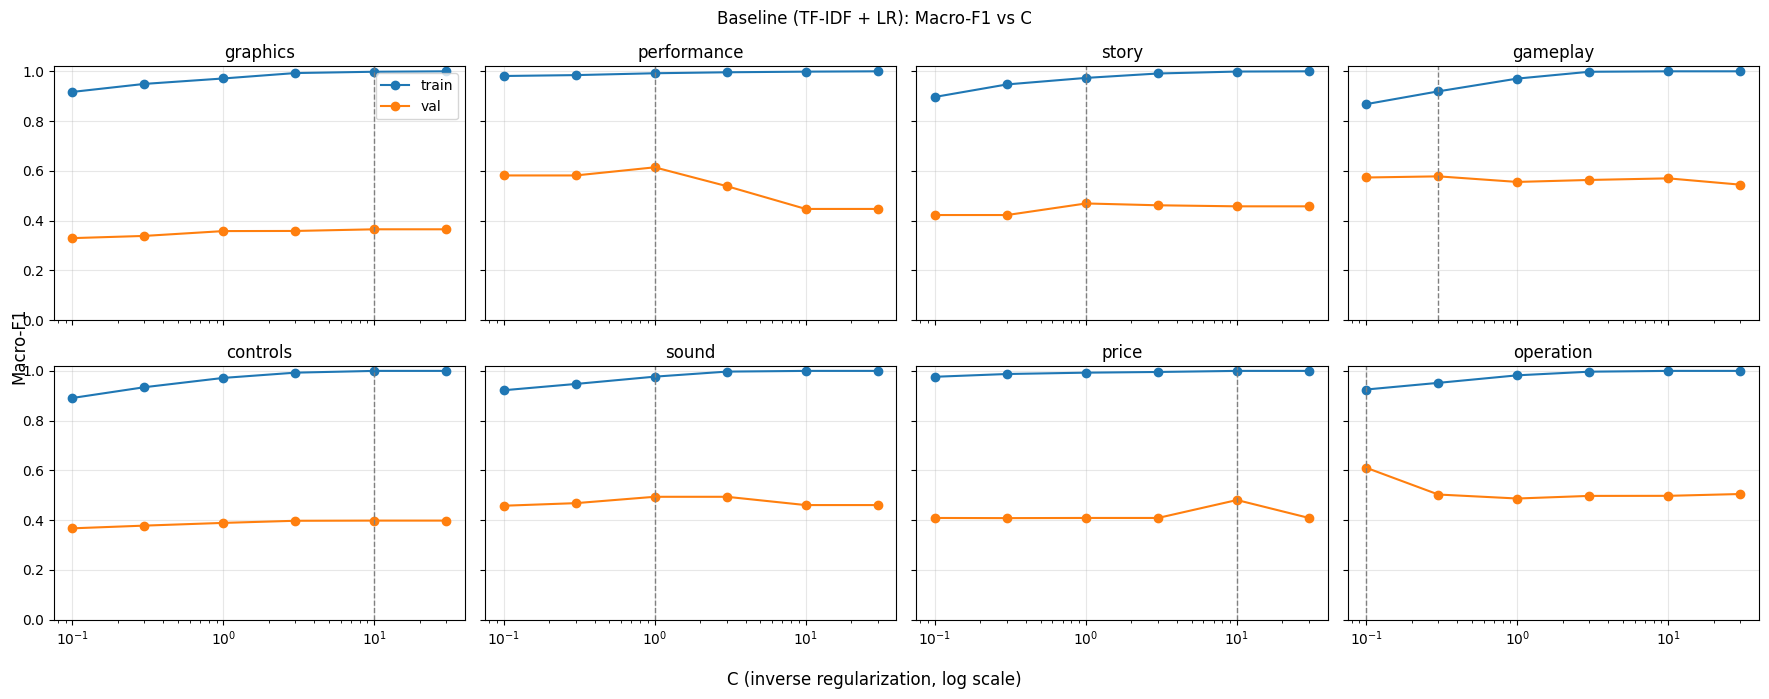

In [6]:
# C에 따른 Train / Val Macro-F1 — 규제가 약해질수록(C↑) Train은 오르고 Val은 꺾이는 과적합 구간 확인
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
for ax, a in zip(axes.ravel(), ASPECTS):
    d = train_log[train_log["aspect"] == a]
    ax.plot(d["C"], d["train_macro_f1"], "o-", label="train")
    ax.plot(d["C"], d["val_macro_f1"], "o-", label="val")
    ax.axvline(BEST_C[a], color="gray", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_title(a); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.supxlabel("C (inverse regularization, log scale)"); fig.supylabel("Macro-F1")
fig.suptitle("Baseline (TF-IDF + LR): Macro-F1 vs C")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_baseline_tuning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. 테스트셋 평가

테스트셋은 튜닝에 한 번도 쓰지 않았다. 테스트 라벨은 학습 데이터와 같은 기준인 **LLM 라벨**이다.

In [7]:
P_te = np.column_stack([clfs[a].predict(X_te) for a in ASPECTS])
res = evaluate(Y_te, P_te)
print(f"테스트 라벨 출처: {'사람 검수' if TEST_SOURCE == 'human' else 'LLM'}")
print("요약:", {k: round(v, 4) for k, v in summary(res).items()})
res.round(3)

테스트 라벨 출처: LLM
요약: {'macro_f1': 0.4916, 'accuracy': 0.8904, 'mention_f1': 0.5921}


,속성,macro_f1,accuracy,mention_f1,n_mentioned
aspect,,,,,
graphics,그래픽,0.381,0.913,0.510,31
performance,최적화,0.429,0.957,0.774,15
story,스토리,0.587,0.910,0.768,52
gameplay,게임성,0.512,0.660,0.787,185
controls,조작감,0.474,0.950,0.400,17
sound,사운드,0.745,0.980,0.500,6
price,가격,0.331,0.937,0.370,22
operation,운영,0.475,0.817,0.628,51
MEAN,평균,0.492,0.890,0.592,379


In [8]:
# 속성 × 클래스별 F1 — 어떤 클래스가 약한지(특히 '보통') 확인
rows = []
for j, a in enumerate(ASPECTS):
    f = f1_score(Y_te[:, j], P_te[:, j], labels=LABELS, average=None, zero_division=0)
    sup = [(Y_te[:, j] == c).sum() for c in LABELS]
    rows.append({**{f"F1-{LABEL_NAMES[c]}": f[i] for i, c in enumerate(LABELS)},
                 **{f"n-{LABEL_NAMES[c]}": sup[i] for i, c in enumerate(LABELS)}})
pd.DataFrame(rows, index=ASPECTS_KO).round(3)

,F1-미언급,F1-긍정,F1-보통,F1-부정,n-미언급,n-긍정,n-보통,n-부정
그래픽,0.954,0.571,0.000,0.000,269,22,4,5
최적화,0.988,0.200,0.000,0.526,285,2,2,11
스토리,0.954,0.725,0.667,0.000,248,45,2,5
게임성,0.725,0.717,0.350,0.255,115,130,29,26
조작감,0.974,0.000,0.500,0.421,283,2,2,13
사운드,0.990,0.500,0.000,0.000,294,6,0,0
가격,0.970,0.353,0.000,0.000,278,12,5,5
운영,0.906,0.261,0.182,0.552,249,13,7,31


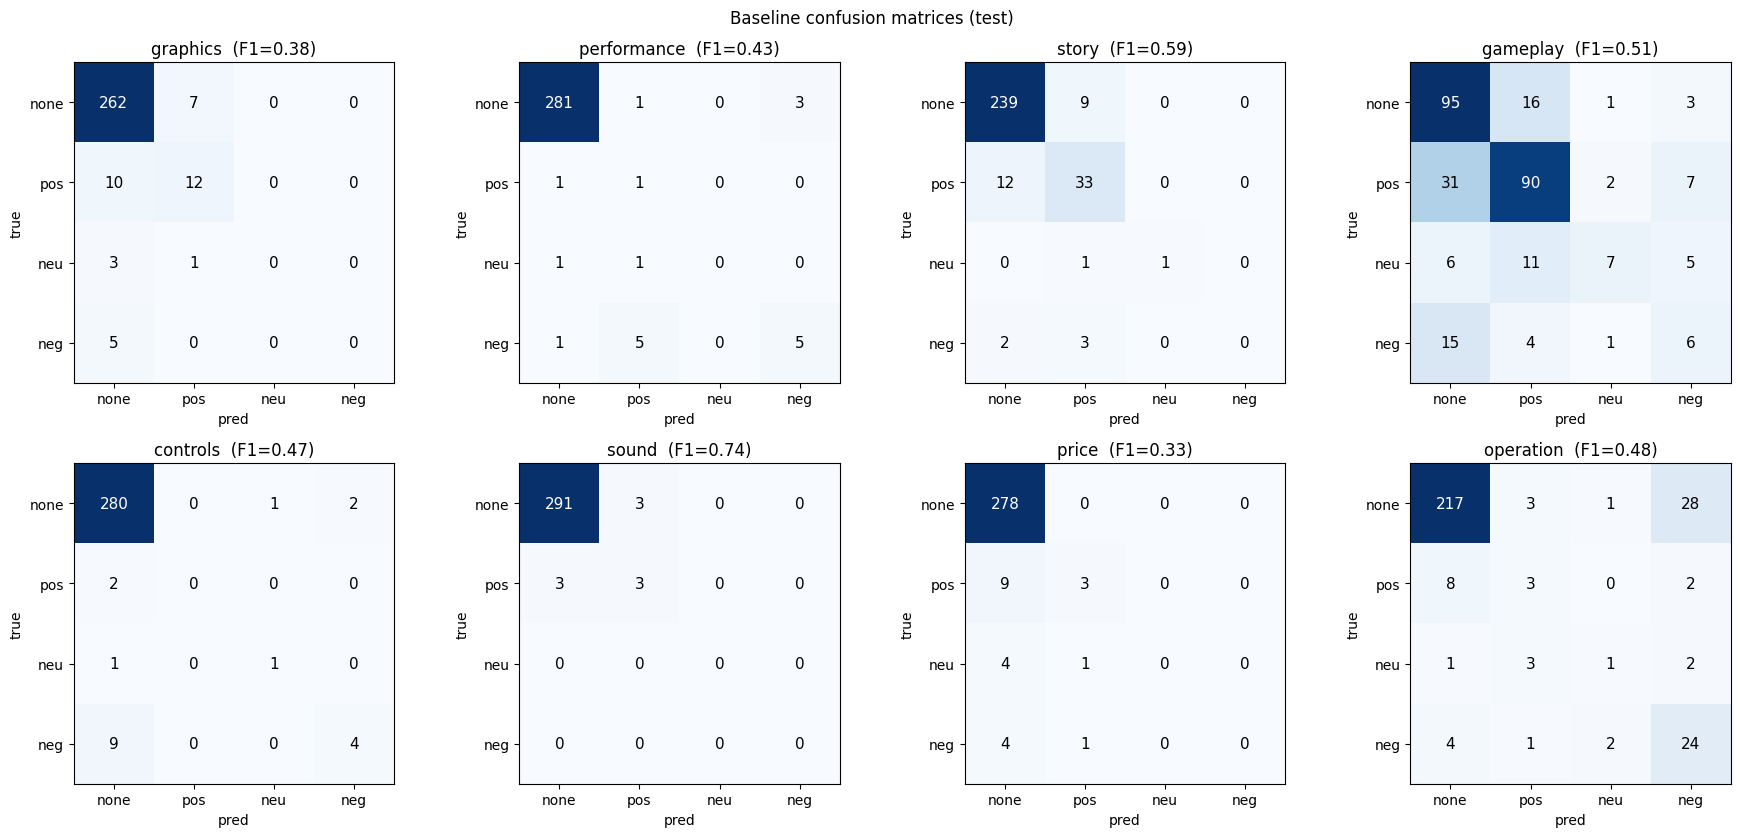

In [9]:
# 혼동행렬 (행: 정답, 열: 예측)
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
ticks = [LABEL_NAMES_EN[c] for c in LABELS]
for j, (ax, a) in enumerate(zip(axes.ravel(), ASPECTS)):
    cm = confusion_matrix(Y_te[:, j], P_te[:, j], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for r in range(4):
        for c in range(4):
            ax.text(c, r, cm[r, c], ha="center", va="center",
                    color="white" if cm[r, c] > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks(range(4), ticks); ax.set_yticks(range(4), ticks)
    ax.set_title(f"{a}  (F1={res.loc[a, 'macro_f1']:.2f})")
    ax.set_xlabel("pred"); ax.set_ylabel("true")
fig.suptitle("Baseline confusion matrices (test)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_baseline_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

### [참고] 사람 검수 시도와의 비교

테스트셋을 사람이 검수해 보았으나(약 150건 정독, 이후는 훑어봄) 경계 사례의 기준이 일정하지 않아 **최종 평가는 LLM 라벨로 통일**했다. 아래는 검수 라벨과 LLM 라벨이 얼마나 달랐는지(일치율·Cohen κ), 검수 라벨로 채점하면 점수가 얼마나 바뀌는지를 참고로 보여준다.

In [10]:
hs_table, hs_agree, N_HUMAN = human_subset_report(ROOT, test, {"Baseline: TF-IDF + LR": P_te})
if N_HUMAN:
    display(hs_agree.round(3))
    display(hs_table.round(4))

[참고] 검수 시도 300행 (기준이 일정하지 않아 최종 평가에는 미사용) | LLM-검수 칸 일치율 0.992 | 검수에서 라벨이 바뀐 리뷰 20건 (7%)


,속성,일치율,Cohen κ,수정 칸 수
graphics,그래픽,0.997,0.982,1
performance,최적화,0.993,0.935,2
story,스토리,1.000,1.000,0
gameplay,게임성,0.963,0.943,11
controls,조작감,0.997,0.970,1
sound,사운드,1.000,1.000,0
price,가격,0.993,0.952,2
operation,운영,0.990,0.967,3


,macro_f1,accuracy,mention_f1
LLM 라벨 (검수 라벨 대비),0.9797,0.9917,0.9758
Baseline: TF-IDF + LR,0.4887,0.8883,0.6019


## 5. 오류 사례

정답과 예측이 다른 칸을 모아 몇 건을 직접 읽어 본다 → README `## 5. 평가 결과` 분석과 Lessons Learned 소재.

In [11]:
err = []
for j, a in enumerate(ASPECTS):
    for i in np.where(Y_te[:, j] != P_te[:, j])[0]:
        err.append({"idx": i, "속성": ASPECTS_KO[j], "정답": LABEL_NAMES[Y_te[i, j]],
                    "예측": LABEL_NAMES[P_te[i, j]], "text": test.loc[i, "text"][:150]})
err = pd.DataFrame(err)
print(f"틀린 칸 {len(err)}개 / 전체 {Y_te.size}칸")
print(pd.crosstab(err["정답"], err["예측"]))     # 어떤 방향으로 틀리는지
pd.set_option("display.max_colwidth", 150)
err.sample(min(12, len(err)), random_state=SEED)

틀린 칸 263개 / 전체 2400칸
예측   긍정  미언급  보통  부정
정답                  
긍정    0   76   2   9
미언급  39    0   3  36
보통   18   16   0   7
부정   14   40   3   0


,idx,속성,정답,예측,text
115,163,게임성,미언급,긍정,발매 초기에 하다가 다시 하고 있는데 이제 게임이라 부를 수준 정도는 됨 최적화도 잘 잡았고 확장팩만 잘 나오길 기대하고 있음
120,171,게임성,긍정,미언급,설산 파트에서 졸다가 겜 지우고 3년동안 묵혀놨다가 갑자기 생각나서 꾹 참고 다시 했는데.. 왜 이제야 했나 라는 생각이 들 정도로 명작임..
259,291,운영,미언급,긍정,진짜 ㅈㄴ 재밌음 사펑 애니 2가 나올때 어떤 업데이트를 할까? 기대됨
226,121,운영,부정,긍정,"빈약한 컨텐츠에 나는 침묵했다. 몬헌 말고도 할 게임이 많았기 때문이다. 최적화 이슈에 나는 침묵했다. 나는 5090 사용자기 때문이다. 오메가 업데이트때 나는 침묵했다. 나는 파이널판타지를 좋아하기 때문이다. 고그마지오스가 업데이트 되었을때, 나를 위해 말해 ..."
66,1,게임성,보통,부정,아직도 씨발 니가와라 에겐 공룡 권법은 버리지 않았구나? 수틀리면 몸부림 존나 치고 멀어지면 하이얏! 니가와라 공룡 권법! 이 지랄 씨발 어찌 저찌 구질구질하게 싸워서 이겨도 멋있는 나 보다는 인생의 쓴맛을 골통으로 쳐 맞은 나 밖에 안남는게 정말 ㅈ같아. 아무...
249,230,운영,미언급,부정,"소소하게 농사지으며 힐링하려고 시작했는데, 일어나면 동선 짜서 물주고, 수확하고, 계란줍고, 우유 짜고, 벌목 하면서 건초 모으고, 나무 수액 모으고, 틈틈이 채광해서 재료 모으고, 시간 뜨면 낚시 해서 돈 모으고, 그 와중에 주민들 선물도 하고 말도 걸어야....."
176,166,조작감,부정,미언급,"최적화 안 좋다는 얘기가 많아서 월드 먼저 구매했다가, 최근 리뷰에 사양 낮은 분도 보여서 구매해봄. 불필요한 묘사 다 끄고 그래픽 품질도 전부 낮췄는데 컴퓨터가 매우 힘들어하심;; 그래픽을 다 낮춰서 하다 보니 옛날 겜 하는 기분이 들 정도로 인게임 그래픽은 ..."
216,43,운영,부정,보통,"고인물, 핵, 버그 등등 문제는 많지만, 게임 자체는 라이트하고 시원시원해서 재밌다."
9,159,그래픽,미언급,긍정,"매력적인 소재, 스토리, 다양한 전술 웰메이드 액션게임 영신도를 통해 캐릭터,보스의 이야기 읽어보는 것도 재미 중 하나. 서유기를 잘 알면 더욱 재밌을 것"
101,121,게임성,부정,미언급,"빈약한 컨텐츠에 나는 침묵했다. 몬헌 말고도 할 게임이 많았기 때문이다. 최적화 이슈에 나는 침묵했다. 나는 5090 사용자기 때문이다. 오메가 업데이트때 나는 침묵했다. 나는 파이널판타지를 좋아하기 때문이다. 고그마지오스가 업데이트 되었을때, 나를 위해 말해 ..."


## 6. 종합 평가(추천/비추천) — 별도 로지스틱 회귀

- 학습: 정제 데이터 중 Test·Val을 제외한 10,677건 (라벨 = `voted_up`)
- 평가: 속성과 **같은** Test 300건 / Val 200건
- 추천이 약 83%로 불균형 → `class_weight="balanced"`, 주지표 Macro-F1

In [12]:
o_tr, o_va, o_te = load_overall_splits(ROOT)
vec_o = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=100000, sublinear_tf=True)
Xo_tr = vec_o.fit_transform(o_tr["text"]); Xo_va = vec_o.transform(o_va["text"]); Xo_te = vec_o.transform(o_te["text"])

o_log, o_best = [], None
for C in C_GRID:
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)
    clf.fit(Xo_tr, o_tr["overall"])
    va_f1 = f1_score(o_va["overall"], clf.predict(Xo_va), average="macro")
    o_log.append({"C": C, "val_macro_f1": round(va_f1, 4)})
    if o_best is None or va_f1 > o_best[1]:
        o_best = (C, va_f1, clf)
clf_o = o_best[2]
print(pd.DataFrame(o_log).to_string(index=False))
print(f"best C={o_best[0]}")

Po_te = clf_o.predict(Xo_te)
overall_res = overall_metrics(o_te["overall"], Po_te)
print("테스트:", {k: round(v, 4) for k, v in overall_res.items()})
pd.DataFrame(confusion_matrix(o_te["overall"], Po_te, labels=[0, 1]),
             index=["정답 비추천", "정답 추천"], columns=["예측 비추천", "예측 추천"])

[종합 평가] Train 10,677 / Val 200 / Test 300 | 추천 비율 Train 0.832, Test 0.837
   C  val_macro_f1
 0.1        0.8031
 0.3        0.8297
 1.0        0.8071
 3.0        0.8235
10.0        0.8131
30.0        0.8419
best C=30
테스트: {'overall_macro_f1': 0.8293, 'overall_accuracy': 0.9067, 'overall_f1_neg': 0.7143}


,예측 비추천,예측 추천
정답 비추천,35,14
정답 추천,14,237


In [13]:
# 속성이 전부 '미언급'으로 예측된 리뷰 — 종합 평가가 이 리뷰들을 어떻게 받아주는지 확인
all_none = (P_te == 0).all(axis=1)
print(f"속성 전부 미언급 예측: {all_none.sum()}건 / {len(test)}건")
demo = test.loc[all_none, ["text"]].copy()
demo["종합(예측)"] = [OVERALL_NAMES[int(v)] for v in Po_te[all_none]]
demo["종합(정답)"] = [OVERALL_NAMES[int(v)] for v in o_te["overall"].values[all_none]]
demo["text"] = demo["text"].str.slice(0, 80)
demo.head(10)

속성 전부 미언급 예측: 86건 / 300건


,text,종합(예측),종합(정답)
0,"소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요..",추천,추천
5,"모드로더와 바닐라 합쳐서 1000시간 넘고, 모바일 까지 합치면 2000시간은 확실히 될 것 같음 내 어린시절 전체를 함께한 게임",추천,추천
8,"모동숲 전에는 나에게 이 게임이 동숲이었어,,",추천,추천
9,어릴때 하베스트문 3년을 넘기지 못하고 아내와 달을 바라보며 마무리하는 끝을 이어서 하는거 같아 좋아요,추천,추천
11,원래 전체 맵 탐방하는 게임을 선호하지 않는 편인데도 이 게임은 즐겨야 할 것이 많아 하기 좋은 것 같음,추천,추천
13,감동 그 너머와 그 이상의 작품 명작이라는 칭호보다는 걸작에 가까운 작품 난 아직 이 재미를 모르는 당신이 안타깝다. 함께 돌아가자 안개의 저편,추천,추천
14,이 재밌는 게임을 마치 일처럼 하지는 마세요,추천,추천
15,현실과 닮은 점이 많아서 깊은 인상을 준 게임,추천,추천
20,내 스타일은 아닌걸로. 그저 그랬다.,추천,추천
21,내 게임 인생은 발더게를 하기 전과 후로 나뉜다.,추천,추천


## 7. 저장 및 로드 확인 (서비스와 같은 방식으로 추론)

In [14]:
bundle = {"vectorizer": vectorizer, "clfs": clfs, "best_C": BEST_C, "aspects": ASPECTS,
          "overall_vectorizer": vec_o, "overall_clf": clf_o}
joblib.dump(bundle, MODEL_DIR / "baseline.joblib", compress=3)

metrics = {"model": "TF-IDF(char 2-4) + LogisticRegression", "test_label_source": TEST_SOURCE,
           **summary(res), "per_aspect": res.drop(index="MEAN")[["macro_f1", "accuracy", "mention_f1"]].round(4).to_dict("index"),
           "best_C": BEST_C, **overall_res, "overall_best_C": o_best[0],
           "human_subset_n": N_HUMAN,
           "human_subset": (hs_table.loc["Baseline: TF-IDF + LR"].to_dict() if N_HUMAN else None)}
(RES_DIR / "baseline_metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2))

pred = test[["recommendationid", "game", "text"]].copy()
for j, a in enumerate(ASPECTS):
    pred[f"{a}_true"], pred[f"{a}_pred"] = Y_te[:, j], P_te[:, j]
pred.to_csv(RES_DIR / "baseline_test_pred.csv", index=False, encoding="utf-8-sig")

size_mb = (MODEL_DIR / "baseline.joblib").stat().st_size / 1e6
print(f"저장 완료: models/baseline.joblib ({size_mb:.1f} MB), results/baseline_metrics.json, results/baseline_test_pred.csv")

저장 완료: models/baseline.joblib (11.6 MB), results/baseline_metrics.json, results/baseline_test_pred.csv


In [15]:
# 저장한 파일을 다시 불러와 새 문장 추론 — app.py에서 쓰는 방식 그대로
m = joblib.load(MODEL_DIR / "baseline.joblib")

def predict(text):
    x = m["vectorizer"].transform([clean_text(text)])
    out = {ko: LABEL_NAMES[int(m["clfs"][a].predict(x)[0])] for a, ko in zip(m["aspects"], ASPECTS_KO)}
    xo = m["overall_vectorizer"].transform([clean_text(text)])
    p_rec = m["overall_clf"].predict_proba(xo)[0, 1]
    return out, p_rec

for s in ["그래픽은 정말 예쁜데 최적화가 엉망이라 프레임이 계속 떨어져요",
          "스토리랑 OST가 미쳤다. 가격도 할인하면 혜자",
          "서버 터지고 핵쟁이 천지. 운영 좀 제대로 해라",
          "소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요.."]:
    asp, p = predict(s)
    print(s); print(f"  → 종합: 추천 {p:.0%} | 속성:", {k: v for k, v in asp.items() if v != "미언급"} or "언급 없음")

그래픽은 정말 예쁜데 최적화가 엉망이라 프레임이 계속 떨어져요
  → 종합: 추천 20% | 속성: {'그래픽': '긍정', '최적화': '부정'}
스토리랑 OST가 미쳤다. 가격도 할인하면 혜자
  → 종합: 추천 97% | 속성: {'스토리': '긍정', '가격': '긍정'}
서버 터지고 핵쟁이 천지. 운영 좀 제대로 해라
  → 종합: 추천 3% | 속성: {'운영': '부정'}
소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요..
  → 종합: 추천 100% | 속성: 언급 없음


## 정리

- 베이스라인 테스트 성능은 `results/baseline_metrics.json`에 저장되어 05 노트북의 **모델 비교표**에서 그대로 불러온다.
- 다음 단계: `05_transformer.ipynb` — KLUE-RoBERTa 멀티헤드 파인튜닝